# Multippel lineær regresjon – KI-bruk

**Problemstilling:** Hvilke bransjer og bedriftsstørrelser tar i bruk kunstig intelligens raskest?

Alle ni bransjer og fire bedriftsstørrelser brukes i regresjonen. Figuren viser tre utvalgte bransjer.

## 1. Data

Årlig vekst i prosentpoeng: `(KI-bruk 2025 − KI-bruk 2023) / 2`. Én rad per bransje og bedriftsstørrelse.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

df = pd.read_csv("SSB_AI_2023-2025.csv")

data = df.pivot(index=["industry", "size"], columns="year", values="ai_any").reset_index()
data["vekst"] = (data[2025] - data[2023]) / 2

## 2. Multippel lineær regresjon

Responsvariabel: årlig KI-vekst. Forklaringsvariabler: bransje og bedriftsstørrelse (0/1-variabler).

In [2]:
X = pd.get_dummies(data[["industry", "size"]], drop_first=True, dtype=int)
y = data["vekst"]

modell = LinearRegression()
modell.fit(X, y)

data["beregnet"] = modell.predict(X)
data["residual"] = data["vekst"] - data["beregnet"]

## 3. Resultater

R², justert R², residualer, gjennomsnittlig vekst og regresjonskoeffisienter. Bransjetabellen omfatter alle ni bransjer; detaljer vises for tre.

In [3]:
r2 = modell.score(X, y)
n = len(data)
p = X.shape[1]
justert_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f"Observasjoner: {n}")
print(f"R²: {r2:.3f}")
print(f"Justert R²: {justert_r2:.3f}")
print(f"Gj.snitt absolutt residual: {data['residual'].abs().mean():.2f} pp/år")

print("\nGjennomsnittlig vekst per bransje (pp/år):")
print(data.groupby("industry")["vekst"].mean().sort_values(ascending=False).round(2).to_string())

print("\nGjennomsnittlig vekst per bedriftsstørrelse (pp/år):")
print(data.groupby("size")["vekst"].mean().sort_values(ascending=False).round(2).to_string())

Observasjoner: 36
R²: 0.667
Justert R²: 0.515
Gj.snitt absolutt residual: 2.58 pp/år

Gjennomsnittlig vekst per bransje (pp/år):
industry
58-63 Informasjon og kommunikasjon                                 21.25
68-75+77-82+95.1 Anna tenesteyting, inklusive veterinærtenester    16.25
46 Agentur- og engroshandel med unntak av motorvogner              14.00
41-43 Byggje- og anleggsverksemd                                   12.00
10-39 Industri, kraftforsyning, vatn, avløp og renovasjon          11.38
47 Detaljhandel med unntak av motorvogner                          10.00
49-53 Transport og lagring                                          9.25
45 Handel med og reparasjon av motorvogner                          7.38
55-56 Overnattings- og serveringsverksemd                           7.25

Gjennomsnittlig vekst per bedriftsstørrelse (pp/år):
size
100 sysselsette eller fleire    14.83
50-99 sysselsette               12.44
20-49 sysselsette               11.06
10-19 sysselsette               

## 4. Tre utvalgte bransjer

Koeffisientene viser forskjeller fra referansegruppen. Tabellen viser faktisk vekst, modellens beregnede vekst og residualer.

In [4]:
bransjer = {
    "58-63 Informasjon og kommunikasjon": "IT",
    "46 Agentur- og engroshandel med unntak av motorvogner": "Engroshandel",
    "55-56 Overnattings- og serveringsverksemd": "Overnatting"
}

valgt = data[data["industry"].isin(bransjer)].copy()
valgt["bransje"] = valgt["industry"].map(bransjer)
koeff = pd.Series(modell.coef_, index=X.columns)

print("Referanse: Industri (10-39), 10–19 ansatte")
print(f"Konstantledd: {modell.intercept_:.2f}")
print("\nBransjeeffekter (pp/år):")
for bransje, navn in bransjer.items():
    print(f"{navn}: {koeff['industry_' + bransje]:+.2f}")

print("\nStørrelseseffekter (pp/år):")
for størrelse in ["20-49 sysselsette", "50-99 sysselsette", "100 sysselsette eller fleire"]:
    print(f"{størrelse}: {koeff['size_' + størrelse]:+.2f}")

print("\nFaktisk vekst, beregnet vekst og residualer (pp/år):")
print(valgt[["bransje", "size", "vekst", "beregnet", "residual"]].round(2).to_string(index=False))

Referanse: Industri (10-39), 10–19 ansatte
Konstantledd: 9.29

Bransjeeffekter (pp/år):
IT: +9.87
Engroshandel: +2.62
Overnatting: -4.13

Størrelseseffekter (pp/år):
20-49 sysselsette: +1.06
50-99 sysselsette: +2.44
100 sysselsette eller fleire: +4.83

Faktisk vekst, beregnet vekst og residualer (pp/år):
     bransje                         size  vekst  beregnet  residual
Engroshandel            10-19 sysselsette   10.5     11.92     -1.42
Engroshandel 100 sysselsette eller fleire   13.5     16.75     -3.25
Engroshandel            20-49 sysselsette   15.5     12.97      2.53
Engroshandel            50-99 sysselsette   16.5     14.36      2.14
 Overnatting            10-19 sysselsette    3.5      5.17     -1.67
 Overnatting 100 sysselsette eller fleire    8.5     10.00     -1.50
 Overnatting            20-49 sysselsette    5.0      6.22     -1.22
 Overnatting            50-99 sysselsette   12.0      7.61      4.39
          IT            10-19 sysselsette   28.0     19.17      8.83
    

## 5. Faktisk og beregnet vekst

Heltrukne linjer = faktisk vekst. Stiplede linjer = beregnet vekst.

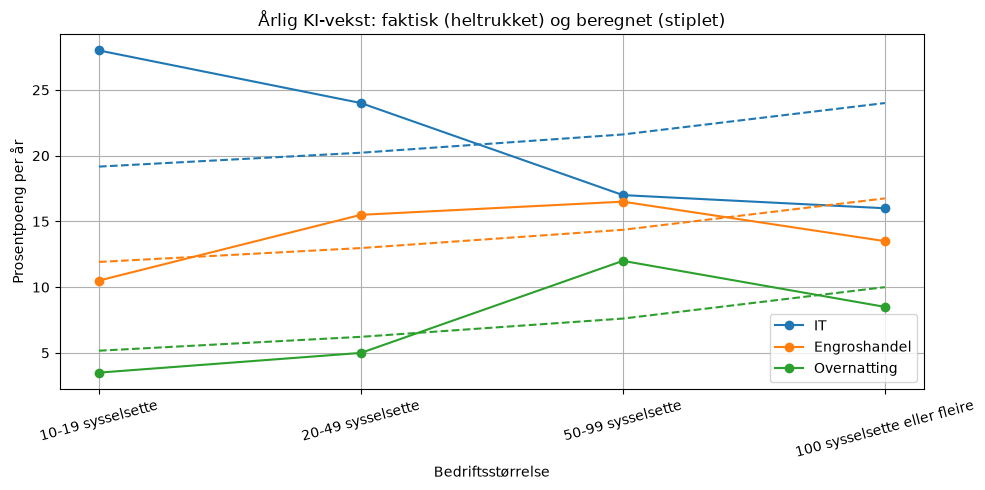

In [5]:
størrelser = ["10-19 sysselsette", "20-49 sysselsette",
              "50-99 sysselsette", "100 sysselsette eller fleire"]

plt.figure(figsize=(10, 5))
for bransje, navn in bransjer.items():
    gruppe = valgt[valgt["industry"] == bransje].set_index("size").loc[størrelser]
    linje, = plt.plot(størrelser, gruppe["vekst"], marker="o", label=navn)
    plt.plot(størrelser, gruppe["beregnet"], "--", color=linje.get_color())

plt.title("Årlig KI-vekst: faktisk (heltrukket) og beregnet (stiplet)")
plt.xlabel("Bedriftsstørrelse")
plt.ylabel("Prosentpoeng per år")
plt.xticks(rotation=15)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("bilder/regresjon_vekst.png", dpi=150)
plt.show()

## 6. Residualanalyse

Residual = faktisk vekst − beregnet vekst. Diagrammet bruker alle 36 observasjoner.

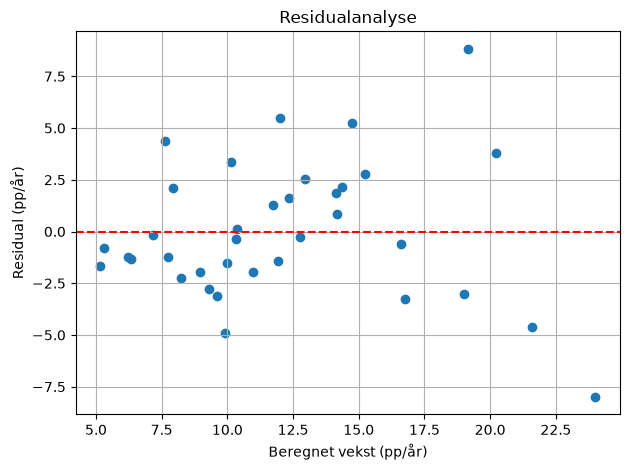

In [6]:
plt.scatter(data["beregnet"], data["residual"])
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Beregnet vekst (pp/år)")
plt.ylabel("Residual (pp/år)")
plt.title("Residualanalyse")
plt.grid(True)
plt.tight_layout()
plt.savefig("bilder/regresjon_residualer.png", dpi=150)
plt.show()